Report- Task 3: Bollinger Bands - mean-reversion vs breakout (+ trend-filter switch)
---------------------------------------------------------------------------
## Core Part
We used daily adjusted closing prices of SPY from Yahoo Finance from January 2005. The first ~220 days only warm up the 200-day moving average, so all strategies are evaluated over the same period, November 2005 – November 2026 (about 21 years). The bands are a 20-day moving average ± 2 rolling standard deviations:
$$Upper_t = MA_{20,t} + 2\,\sigma_{20,t}, \qquad Lower_t = MA_{20,t} - 2\,\sigma_{20,t}$$
Mean-reversion (MR): buy when the close touches the lower band, sell (go flat) when it touches the upper band.
Breakout (BO): buy when the close breaks the upper band, sell (go flat) when it breaks the lower band.
A position is held until the opposite signal. A signal from the close of day t is applied to the return of day t+1, so no future data is used. Each change in position costs 5 bps per side; buy-and-hold pays the entry cost once. Sharpe ratios use a zero risk-free rate.


| Strategy | Ann. return | Volatility | Sharpe | Max drawdown | Time in market | Trades (sides) | Total cost |
|---|---|---|---|---|---|---|---|
| Buy & hold | 11.1% | 19.1% | 0.64 | -55.2% | 100% | 1 | 0.0% |
| Mean-reversion | 7.4% | 16.9% | 0.51 | -50.1% | 53% | 101 | 5.0% |
| Breakout | 2.9% | 9.1% | 0.36 | -21.2% | 47% | 102 | 5.1% |

Neither rule beats buy-and-hold after costs: both earn less and have a lower Sharpe ratio. On SPY, mean-reversion clearly works better than breakout. Buying the index after a sharp fall and selling after a sharp rise captures short-term rebounds, while breakouts above the upper band tend to fade instead of continuing.

The two rules differ mainly in their risk. Mean-reversion bought the dips in 2008 and had no stop-loss, so it held through the crash and its drawdown (-50%) is almost as deep as buy-and-hold's. Breakout was sold out after the first lower-band break, so it avoided most of the 2008 crash (drawdown -21%). Since 2012, however, it has gained very little, because it is often whipsawed in and out of a rising market.

Transaction costs are not what drives the results: each rule trades about 5 times a year, and the costs add up to only about 5% over 21 years. The main cost of both rules is being out of the market about half the time during a long bull market.

**Equity curves.** The chart of the growth of \$1 shows the same picture. Buy-and-hold ends near \$9, mean-reversion near \$4.5 and breakout below \$2. Breakout is ahead of every other strategy until about 2012 because it was out of the market during the 2008 crash, and after that it barely moves. Mean-reversion falls as deeply as buy-and-hold in 2008–09 but then grows steadily, especially after 2020.

**Bands chart (last 2 years).** The zoomed chart shows why mean-reversion carries crash risk. In the March–April 2025 sell-off the price touched the lower band many times on the way down, so the rule bought early and held through the fall before the rebound. After the April 2026 bottom the price stayed above the upper band during the rally. This is the kind of move a breakout rule needs, but such moves are rare for SPY.

**Report - Stretch Part**

The trend filter is the slope of the 200-day moving average over the last 20 days:

$$slope_t = \frac{MA_{200,t}}{MA_{200,t-20}} - 1$$

If $|slope_t| < 1\%$ the market is treated as flat and the MR position is used; otherwise the market is trending and the BO position is used. 63% of days are classified as trending.

| Strategy | Ann. return | Volatility | Sharpe | Max drawdown | Trades (sides) |
|---|---|---|---|---|---|
| Buy & hold | 11.1% | 19.1% | 0.64 | -55.2% | 1 |
| Mean-reversion (fixed) | 7.4% | 16.9% | 0.51 | -50.1% | 101 |
| Breakout (fixed) | 2.9% | 9.1% | 0.36 | -21.2% | 102 |
| Switched (1%) | 5.5% | 13.6% | 0.46 | -33.5% | 150 |

With the 1% threshold, the switched rule ends up between the two fixed rules. It beats breakout but not mean-reversion. Its drawdown (-34%) is much smaller than mean-reversion's, but it trades about 50% more.

The 1% threshold is itself a parameter, so we checked how sensitive the result is and avoided picking it with hindsight. We chose the threshold on the first half of the sample only (until 12 May 2016) and evaluated it once on the second half.

| Threshold | Sharpe (full) | Sharpe (1st half) | Sharpe (2nd half) |
|---|---|---|---|
| 0.25% | 0.41 | 0.39 | 0.42 |
| 0.5% | 0.51 | **0.53** | 0.48 |
| 0.75% | 0.52 | 0.47 | 0.57 |
| 1% | 0.46 | 0.43 | 0.49 |
| 1.5% | 0.39 | 0.29 | 0.48 |
| 2% | 0.41 | 0.26 | 0.55 |
| 3% | 0.53 | 0.28 | 0.79 |
| *MR fixed* | *0.51* | *0.26* | *0.82* |
| *BO fixed* | *0.36* | *0.43* | *0.28* |
| *Buy & hold* | *0.64* | *0.44* | *0.88* |

The threshold chosen on the 1st half is **0.5%** (in-sample Sharpe 0.53). Out of sample it gives a Sharpe of **0.48**, compared with MR 0.82, BO 0.28 and buy-and-hold 0.88 over the same period.

The switched rule does **not** reliably beat the fixed rules:
- **In sample** it looks good: at 0.5% it beats both fixed rules (0.53 vs 0.43 for BO and 0.26 for MR) and even buy-and-hold.
- **Out of sample** it only beats breakout and falls far behind mean-reversion. Its own Sharpe drops only a little (0.53 → 0.48), but the ranking flips.
- **Across thresholds** the full-sample Sharpe moves between 0.39 and 0.53 with no clear pattern. No threshold is clearly better than simply using mean-reversion (0.51).

The reason is that the better fixed rule changes over time. Breakout won in the first half thanks to the 2008 crash, while mean-reversion won in the second half, when sell-offs (2018, 2020, 2022, 2025) were quickly reversed. A switch only helps if the filter identifies the regime in advance. The 200-day MA slope reacts slowly, so it often switches after the regime has already changed. Using the absolute slope also treats a falling market as "trending", so in long/flat form the breakout leg mostly keeps the strategy out of the market in downtrends. That explains the smaller drawdown, but not a higher Sharpe.

**Conclusion.** Overall, on SPY none of the Bollinger rules, fixed or switched, beat buy-and-hold on a risk-adjusted basis after costs. Their main benefit is a smaller drawdown. Mean-reversion fits an equity index better than breakout, and the trend-filter switch does not add value out of sample.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


TICKER = "SPY"
START = "2005-01-01"
BB_WIN, BB_K = 20, 2.0      # Bollinger window and band width (sigmas)
COST_BPS = 5                # per side
ALLOW_SHORT = False         # False: "sell" = exit to flat; True: "sell" = go short
MA_LONG = 200               # trend filter MA
SLOPE_LAG = 20              # slope = % change of MA200 over 20 trading days
FLAT_THRESH = 0.01          # |slope| below 1% over 20 days = "flat" market
RF = 0.0                    # annual risk-free rate for Sharpe (0 = excess over cash ignored)

COST = COST_BPS / 1e4
SHORT = -1.0 if ALLOW_SHORT else 0.0

## 1. Data


In [4]:
def load_prices(ticker, start):
    try:
        import yfinance as yf
        d = yf.download(ticker, start=start, auto_adjust=True, progress=False)
        px = d["Close"].squeeze().dropna()
        if len(px) > 1000:
            return px.rename(ticker)
    except Exception as e:
        print(f"yfinance failed ({e}); trying Stooq")
    url = f"https://stooq.com/q/d/l/?s={ticker.lower()}.us&i=d"
    d = pd.read_csv(url, index_col="Date", parse_dates=True)
    return d["Close"].loc[start:].rename(ticker)      # Stooq closes are split/div-adjusted


px = load_prices(TICKER, START)
ret = px.pct_change()

ma = px.rolling(BB_WIN).mean()
sd = px.rolling(BB_WIN).std()           # sample std (ddof=1)
upper, lower = ma + BB_K * sd, ma - BB_K * sd

ma_long = px.rolling(MA_LONG).mean()
slope = ma_long / ma_long.shift(SLOPE_LAG) - 1

# common sample: start once every indicator exists, so all strategies cover the same days
start_day = slope.first_valid_index()
print(f"{TICKER}: {px.index[0]:%Y-%m-%d} to {px.index[-1]:%Y-%m-%d}; "
      f"evaluation from {start_day:%Y-%m-%d} ({px.loc[start_day:].shape[0]} days)")

SPY: 2005-01-03 to 2026-11-11; evaluation from 2005-11-14 (5281 days)


## 2.Rules


In [5]:
def state_machine(buy, sell, short=SHORT):
    """+1 after a buy signal, `short` after a sell signal, held until the next signal."""
    sig = pd.Series(np.nan, index=buy.index)
    sig[sell] = short
    sig[buy] = 1.0                       # bands never overlap, so no buy/sell clash
    return sig.ffill().fillna(0.0)


pos_mr = state_machine(buy=px <= lower, sell=px >= upper)
pos_bo = state_machine(buy=px >= upper, sell=px <= lower)


def switched(thresh):
    trending = slope.abs() >= thresh
    return pd.Series(np.where(trending, pos_bo, pos_mr), index=px.index)


def backtest(pos, start=start_day, end=None):
    """Net daily returns. Position decided at close t earns the return of t+1."""
    held = pos.shift(1).loc[start:end].fillna(0.0)   # position actually held during day t
    held.iloc[0] = 0.0                   # every test starts flat (fair vs buy & hold)
    turnover = held.diff().abs()
    turnover.iloc[0] = abs(held.iloc[0])
    gross = held * ret.loc[start:end]
    net = gross - turnover * COST
    return pd.DataFrame({"net": net, "pos": held, "turnover": turnover})


def buy_hold(start=start_day, end=None):
    r = ret.loc[start:end].copy()
    r.iloc[0] = -COST                    # bought at the close of day 0, one entry cost
    turnover = pd.Series(0.0, index=r.index)
    turnover.iloc[0] = 1.0
    return pd.DataFrame({"net": r, "pos": 1.0, "turnover": turnover})


def stats(bt):
    r = bt["net"]
    n_years = len(r) / 252
    eq = (1 + r).cumprod()
    vol = r.std() * np.sqrt(252)
    return pd.Series({
        "Ann. return (CAGR)": eq.iloc[-1] ** (1 / n_years) - 1,
        "Ann. volatility": vol,
        "Sharpe": (r.mean() * 252 - RF) / vol if vol > 0 else np.nan,
        "Max drawdown": (eq / eq.cummax() - 1).min(),
        "Time in market": (bt["pos"] != 0).mean(),
        "Trades (sides)": bt["turnover"].sum(),
        "Total cost paid (sum of daily cost)": bt["turnover"].sum() * COST,
    })

## 3.Core Results

In [6]:
results = {
    "Buy & hold": buy_hold(),
    "Mean-reversion": backtest(pos_mr),
    "Breakout": backtest(pos_bo),
    f"Switched (|slope|>={FLAT_THRESH:.1%})": backtest(switched(FLAT_THRESH)),
}
table = pd.DataFrame({k: stats(v) for k, v in results.items()})

print(f"=== {TICKER}, Bollinger {BB_WIN}d/{BB_K}σ, cost {COST_BPS} bps/side, "
          f"{'long/short' if ALLOW_SHORT else 'long/flat'} ===\n"
          f"{table.round(3).to_string()}")

# share of days classified as trending
trend_share = (slope.loc[start_day:].abs() >= FLAT_THRESH).mean()
print(f"\nDays classified as trending: {trend_share:.1%}")

=== SPY, Bollinger 20d/2.0σ, cost 5 bps/side, long/flat ===
                                     Buy & hold  Mean-reversion  Breakout  Switched (|slope|>=1.0%)
Ann. return (CAGR)                        0.111           0.074     0.029                     0.055
Ann. volatility                           0.191           0.169     0.091                     0.136
Sharpe                                    0.644           0.509     0.359                     0.460
Max drawdown                             -0.552          -0.501    -0.212                    -0.335
Time in market                            1.000           0.533     0.467                     0.578
Trades (sides)                            1.000         101.000   102.000                   150.000
Total cost paid (sum of daily cost)       0.000           0.050     0.051                     0.075

Days classified as trending: 63.0%


## 4.Stretch: Roburtness of the  switch

In [7]:
grid = [0.0025, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03]
mid = px.loc[start_day:].index[len(px.loc[start_day:]) // 2]


def sharpe(bt):
    return stats(bt)["Sharpe"]


rows = []
for th in grid:
    sw = switched(th)
    rows.append({
        "threshold": th,
        "Sharpe full": sharpe(backtest(sw)),
        "Sharpe 1st half": sharpe(backtest(sw, end=mid)),
        "Sharpe 2nd half": sharpe(backtest(sw, start=mid)),
    })
rob = pd.DataFrame(rows).set_index("threshold")
fixed = pd.DataFrame({
    name: {"Sharpe full": sharpe(backtest(p)),
           "Sharpe 1st half": sharpe(backtest(p, end=mid)),
           "Sharpe 2nd half": sharpe(backtest(p, start=mid))}
    for name, p in [("MR fixed", pos_mr), ("BO fixed", pos_bo)]
}).T
bh = {"Sharpe full": sharpe(buy_hold()), "Sharpe 1st half": sharpe(buy_hold(end=mid)),
      "Sharpe 2nd half": sharpe(buy_hold(start=mid))}

best_th = rob["Sharpe 1st half"].idxmax()
oos = rob.loc[best_th, "Sharpe 2nd half"]
block = (f"\n=== Switch: threshold grid (split at {mid:%Y-%m-%d}) ===\n"
         f"{rob.round(3).to_string()}\n\nFixed rules:\n{fixed.round(3).to_string()}\n"
         f"Buy & hold: " + ", ".join(f"{k} {v:.3f}" for k, v in bh.items()) + "\n\n"
         f"Threshold chosen on 1st half: {best_th:.2%} "
         f"(IS Sharpe {rob.loc[best_th, 'Sharpe 1st half']:.3f}) -> OOS Sharpe {oos:.3f}\n"
         f"OOS vs fixed rules: MR {fixed.loc['MR fixed', 'Sharpe 2nd half']:.3f}, "
         f"BO {fixed.loc['BO fixed', 'Sharpe 2nd half']:.3f}")
print(block)


=== Switch: threshold grid (split at 2016-05-12) ===
           Sharpe full  Sharpe 1st half  Sharpe 2nd half
threshold                                               
0.0025           0.406            0.389            0.424
0.0050           0.506            0.531            0.481
0.0075           0.521            0.474            0.566
0.0100           0.460            0.430            0.487
0.0150           0.390            0.293            0.481
0.0200           0.407            0.261            0.547
0.0300           0.527            0.277            0.787

Fixed rules:
          Sharpe full  Sharpe 1st half  Sharpe 2nd half
MR fixed        0.509            0.256            0.815
BO fixed        0.359            0.432            0.284
Buy & hold: Sharpe full 0.644, Sharpe 1st half 0.442, Sharpe 2nd half 0.879

Threshold chosen on 1st half: 0.50% (IS Sharpe 0.531) -> OOS Sharpe 0.481
OOS vs fixed rules: MR 0.815, BO 0.284


## 5.Charts

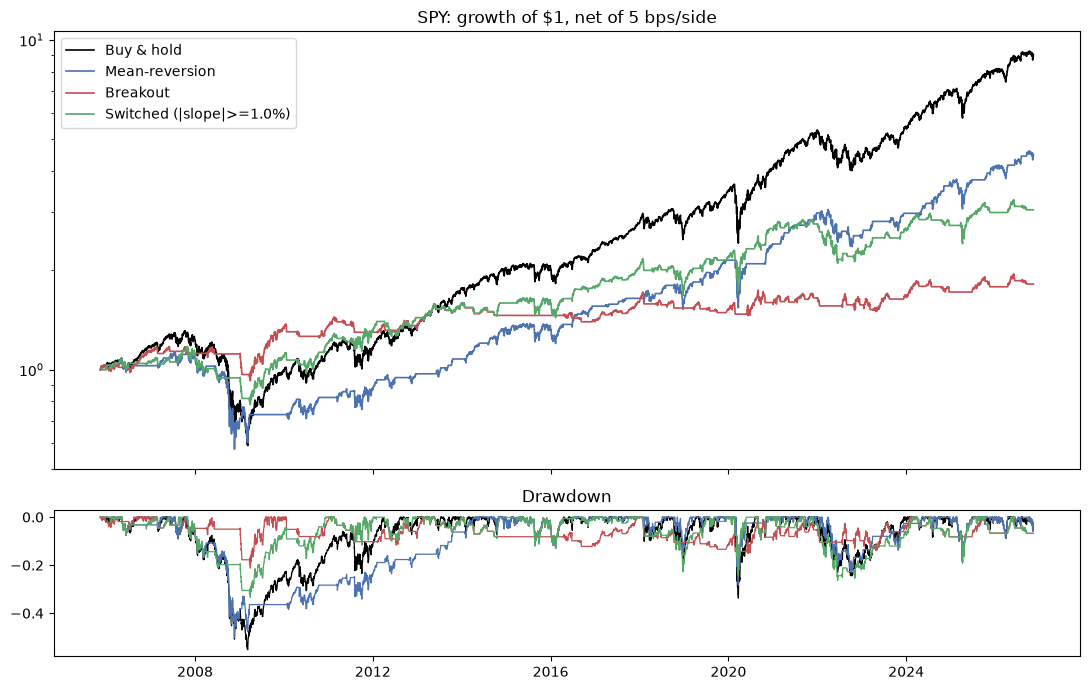

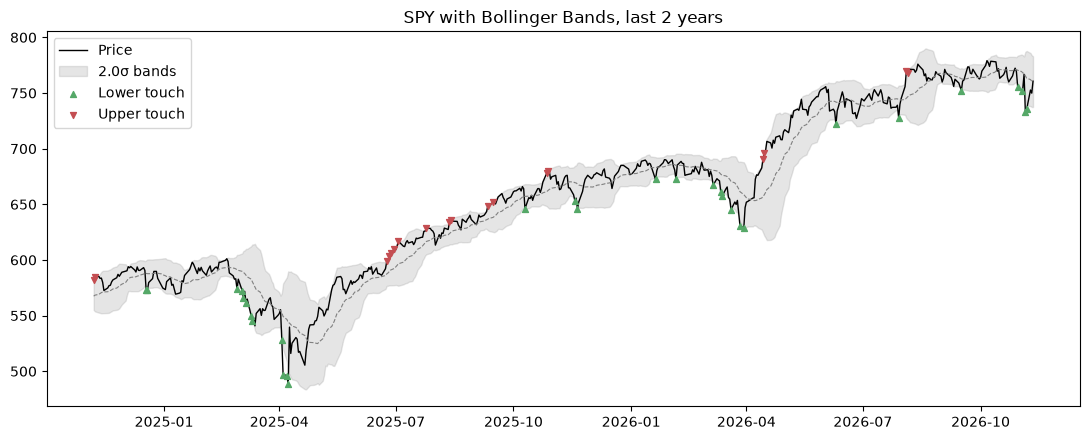

In [8]:
colors = ["black", "#4c72b0", "#c44e52", "#55a868"]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
for (name, bt), c in zip(results.items(), colors):
    eq = (1 + bt["net"]).cumprod()
    axes[0].plot(eq.index, eq, label=name, color=c, lw=1.2)
    dd = eq / eq.cummax() - 1
    axes[1].plot(dd.index, dd, color=c, lw=0.9)
axes[0].set_yscale("log")
axes[0].set_title(f"{TICKER}: growth of $1, net of {COST_BPS} bps/side")
axes[0].legend()
axes[1].set_title("Drawdown")
plt.tight_layout()
plt.show()

# zoom: bands + positions over a recent 2-year window
z = px.index[-504:]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(z, px.loc[z], color="black", lw=1, label="Price")
ax.fill_between(z, lower.loc[z], upper.loc[z], color="grey", alpha=0.2, label=f"{BB_K}σ bands")
ax.plot(z, ma.loc[z], color="grey", lw=0.8, ls="--")
ax.scatter(z[(px <= lower).loc[z]], px.loc[z][(px <= lower).loc[z]], marker="^",
           color="#55a868", s=18, label="Lower touch", zorder=3)
ax.scatter(z[(px >= upper).loc[z]], px.loc[z][(px >= upper).loc[z]], marker="v",
           color="#c44e52", s=18, label="Upper touch", zorder=3)
ax.set_title(f"{TICKER} with Bollinger Bands, last 2 years")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()